# MDST 3D Generative Pipeline — Week 3 — **SOLUTIONS**

> This is `week3_blender_export.ipynb` with all TODOs
> filled in. Every structure check should come back `[PASS]`, the export
> should run clean in Blender, and the preview should render.


## Part 0 — Setup

In [11]:
import os, sys, subprocess, shutil, ast
from pathlib import Path

_here = Path.cwd().resolve()
for _c in [_here, *_here.parents]:
    if (_c / "citygen" / "city_grid.py").exists():
        os.chdir(_c); break
else:
    raise RuntimeError("Couldn't find the repo root (folder containing citygen/city_grid.py). "
                       "Put this notebook inside your project folder and restart the kernel.")

REPO = Path.cwd()
(REPO / "data").mkdir(exist_ok=True)
(REPO / "scripts").mkdir(exist_ok=True)
print("repo root:", REPO)

repo root: /Users/kevinschool/Documents/MDST-3D-Generator-F26


In [12]:
def check(label, condition, hint=""):
    """Reports PASS/FAIL. Never raises -- a failure should never stop you."""
    if condition:
        print(f"[PASS] {label}")
    else:
        print(f"[FAIL] {label}")
        if hint:
            for line in hint.strip().splitlines():
                print(f"       {line}")
    return bool(condition)

print("check() ready")

check() ready


In [13]:
def find_blender():
    exe = shutil.which("blender")
    if exe:
        return exe
    candidates = [
        "/Applications/Blender.app/Contents/MacOS/Blender",          # macOS
        "/Applications/Blender/Blender.app/Contents/MacOS/Blender",
        "/usr/bin/blender", "/usr/local/bin/blender", "/snap/bin/blender",  # Linux
    ]
    candidates += [str(p) for p in Path("/Applications").glob("Blender*/Contents/MacOS/Blender")]
    for base in (r"C:\Program Files\Blender Foundation", r"C:\Program Files (x86)\Blender Foundation"):
        candidates += [str(p) for p in Path(base).glob("Blender*/blender.exe")] if Path(base).exists() else []
    for c in candidates:
        if Path(c).exists():
            return c
    return None


BLENDER = find_blender()

if BLENDER:
    print("Blender found:", BLENDER)
    try:
        v = subprocess.run([BLENDER, "--version"], capture_output=True, text=True, timeout=120)
        print(v.stdout.strip().splitlines()[0] if v.stdout.strip() else "(no version output)")
    except Exception as e:
        print("found the binary but couldn't run it:", e)
else:
    print("Blender NOT found automatically.")
    print()
    print("Set it manually in the next cell, e.g.:")
    print('  BLENDER = "/Applications/Blender.app/Contents/MacOS/Blender"   # macOS')
    print(r'  BLENDER = r"C:\Program Files\Blender Foundation\Blender 4.2\blender.exe"  # Windows')
    print('  BLENDER = "/usr/bin/blender"  # Linux')

Blender found: /Applications/Blender.app/Contents/MacOS/Blender
Blender 3.3.0


In [14]:
# If the cell above didn't find Blender, uncomment and edit this line:
# BLENDER = "/Applications/Blender.app/Contents/MacOS/Blender"

print("BLENDER =", BLENDER)

BLENDER = /Applications/Blender.app/Contents/MacOS/Blender


In [15]:
CITY_NPZ = REPO / "data" / "week3_city.npz"

if CITY_NPZ.exists():
    print(f"using existing {CITY_NPZ.name}")
else:
    try:
        sys.path.insert(0, str(REPO))
        from citygen import CityGrid, generate_terrain, generate_buildings
        th, iw = generate_terrain(128, archetype="hills", seed=0, relief=1.2)
        bh, lu = generate_buildings(th, iw, archetype="polycentric", num_clusters=3,
                                    density=0.6, cluster_tightness=0.6,
                                    green_amount=0.25, road_continuity=0.7, seed=1)
        CityGrid(size=128, terrain_height=th, is_water=iw,
                 building_height=bh, land_use=lu).save(str(CITY_NPZ))
        print(f"generated {CITY_NPZ.name} using the Week 2 code")
    except Exception as e:
        print(f"Couldn't generate a city from the citygen package: {type(e).__name__}: {e}")

check("a city .npz exists to export", CITY_NPZ.exists())

using existing week3_city.npz
[PASS] a city .npz exists to export


True

---

## Part 2 — The export script (solved)

Teaching notes on the five places students get stuck:

1. **Vertex height** — the heightmap is 0–1. Without `HEIGHT_SCALE` the
   terrain is a flat sheet next to 8-unit-tall buildings. Water pinned to
   exactly `0.0` is what makes lakes read as level.
2. **Face winding** — vertices must go *around* the quad, not diagonally
   across it. `(y,x) → (y,x+1) → (y+1,x+1) → (y+1,x)`. Getting this wrong
   gives bow-tie faces; a common symptom is a terrain that looks shredded.
3. **`material_index`** — it's a position in the mesh's material slot list,
   not a colour. Order of `slot_names` is what the indices mean.
4. **Height tiers** — percentiles, not fixed cutoffs, so the colouring
   adapts to each city's own height range.
5. **Box corner order** — `top` must use the *same* corner order as
   `bottom`, because the side-wall loop pairs them by index. A different
   order gives twisted walls.


In [16]:
%%writefile scripts/export_to_blender.py
"""
Import a saved CityGrid into Blender and build 3D geometry from it.

Must be run with Blender's own Python, not your venv:

    blender --background --python scripts/export_to_blender.py -- data/city.npz

Drop --background to have the GUI open with the result already loaded.

Builds a "Terrain" mesh coloured by land use, and a "Buildings" mesh of one
box per building cell coloured by height tier, then saves a .blend next to
the input .npz.

NOTE: numpy only. Blender does not bundle scipy, so importing it here would
fail with ModuleNotFoundError.
"""
import sys
from pathlib import Path

import bpy
import bmesh
import numpy as np

# Blender passes its own args first, then "--", then ours.
argv = sys.argv[sys.argv.index("--") + 1:] if "--" in sys.argv else []
if not argv:
    raise SystemExit("usage: blender --background --python export_to_blender.py -- <city.npz>")

CITY_PATH = argv[0]

CELL_SIZE = 1.0             # world size of one grid cell
HEIGHT_SCALE = 8.0          # terrain_height is 0-1, so scale it up to be visible
BUILDING_HEIGHT_SCALE = 1.0

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from citygen import CityGrid, LAND_BUILDING, LAND_GREEN, LAND_ROAD  # noqa: E402

# name -> (R, G, B), each 0-1. Edit these to change the palette.
COLORS = {
    "ground":          (0.78, 0.72, 0.55),
    "green":           (0.30, 0.55, 0.25),
    "road":            (0.15, 0.15, 0.16),
    "water":           (0.10, 0.35, 0.55),
    "building_short":  (0.55, 0.55, 0.55),
    "building_mid":    (0.70, 0.62, 0.45),
    "building_tall":   (0.35, 0.42, 0.52),
}


# --------------------------------------------------------------------
# helpers
# --------------------------------------------------------------------

def get_or_create_material(name: str):
    """Fetch a material by name, creating it from COLORS if it doesn't exist."""
    mat = bpy.data.materials.get(name)
    if mat is not None:
        return mat
    mat = bpy.data.materials.new(name)
    mat.use_nodes = True
    bsdf = mat.node_tree.nodes.get("Principled BSDF")
    r, g, b = COLORS[name]
    if bsdf is not None:
        bsdf.inputs["Base Color"].default_value = (r, g, b, 1.0)
    mat.diffuse_color = (r, g, b, 1.0)   # also used by solid viewport shading
    return mat


def clear_scene():
    """Delete everything, so re-running doesn't stack cities on top of each other."""
    bpy.ops.object.select_all(action="SELECT")
    bpy.ops.object.delete(use_global=False)


# --------------------------------------------------------------------
# terrain mesh
# --------------------------------------------------------------------

def build_terrain(city: CityGrid):
    """One vertex per grid cell, joined into quads, coloured by land use."""
    size = city.size
    mesh = bpy.data.meshes.new("TerrainMesh")
    bm = bmesh.new()

    # material slots, in a fixed order -- face.material_index is an index
    # into THIS list, so the order here is what the indices below mean
    slot_names = ["ground", "water", "green", "road"]

    verts = np.empty((size, size), dtype=object)
    for y in range(size):
        for x in range(size):
            # SOLUTION 1: water sits flat at exactly 0.0 so lakes are level;
            # land is the 0-1 heightmap scaled up to world units.
            if city.is_water[y, x]:
                z = 0.0
            else:
                z = float(city.terrain_height[y, x]) * HEIGHT_SCALE

            verts[y, x] = bm.verts.new((x * CELL_SIZE, y * CELL_SIZE, z))

    for y in range(size - 1):
        for x in range(size - 1):
            # SOLUTION 2: vertices listed going AROUND the quad. Swapping the
            # last two would cross the diagonal and make a bow-tie face.
            face = bm.faces.new((verts[y, x], verts[y, x + 1],
                                 verts[y + 1, x + 1], verts[y + 1, x]))

            # SOLUTION 3: material_index is a position in slot_names.
            # Water wins over everything, then green, then road, else ground.
            if city.is_water[y, x]:
                face.material_index = slot_names.index("water")
            elif city.land_use[y, x] == LAND_GREEN:
                face.material_index = slot_names.index("green")
            elif city.land_use[y, x] == LAND_ROAD:
                face.material_index = slot_names.index("road")
            else:
                face.material_index = slot_names.index("ground")

    bmesh.ops.recalc_face_normals(bm, faces=bm.faces[:])
    bm.to_mesh(mesh)
    bm.free()

    for name in slot_names:
        mesh.materials.append(get_or_create_material(name))

    obj = bpy.data.objects.new("Terrain", mesh)
    bpy.context.collection.objects.link(obj)
    return obj


# --------------------------------------------------------------------
# buildings mesh
# --------------------------------------------------------------------

def build_buildings(city: CityGrid):
    """One box per building cell, all merged into a single mesh object."""
    mesh = bpy.data.meshes.new("BuildingsMesh")
    bm = bmesh.new()

    slot_names = ["building_short", "building_mid", "building_tall"]

    # Height tiers from THIS city's own distribution, so the colouring
    # adapts instead of using fixed cutoffs that would look wrong on a very
    # short or very tall city.
    building_cells = np.argwhere(city.land_use == LAND_BUILDING)
    heights = city.building_height[city.land_use == LAND_BUILDING]
    heights = heights[heights > 0]
    if len(heights) > 0:
        low_cut, high_cut = np.percentile(heights, [40, 75])
    else:
        low_cut, high_cut = 0.0, 0.0

    for y, x in building_cells:
        base_z = float(city.terrain_height[y, x]) * HEIGHT_SCALE
        h = float(city.building_height[y, x]) * BUILDING_HEIGHT_SCALE
        if h <= 0:
            continue

        cx, cy = x * CELL_SIZE, y * CELL_SIZE
        half = CELL_SIZE * 0.4   # < 0.5 leaves a gap so neighbours don't fuse

        # SOLUTION 4: bottom 40% short, next 35% mid, top 25% tall.
        if h < low_cut:
            mat_idx = slot_names.index("building_short")
        elif h < high_cut:
            mat_idx = slot_names.index("building_mid")
        else:
            mat_idx = slot_names.index("building_tall")

        bottom = [
            bm.verts.new((cx - half, cy - half, base_z)),
            bm.verts.new((cx + half, cy - half, base_z)),
            bm.verts.new((cx + half, cy + half, base_z)),
            bm.verts.new((cx - half, cy + half, base_z)),
        ]
        # SOLUTION 5: same four corners, same order, lifted by h. The side-wall
        # loop below pairs bottom[i] with top[i], so the order must match.
        top = [
            bm.verts.new((cx - half, cy - half, base_z + h)),
            bm.verts.new((cx + half, cy - half, base_z + h)),
            bm.verts.new((cx + half, cy + half, base_z + h)),
            bm.verts.new((cx - half, cy + half, base_z + h)),
        ]

        # close the box. top[::-1] reverses the roof's winding order so its
        # normal points up instead of down.
        new_faces = [bm.faces.new(bottom), bm.faces.new(top[::-1])]
        for i in range(4):
            j = (i + 1) % 4
            new_faces.append(bm.faces.new((bottom[i], bottom[j], top[j], top[i])))

        for face in new_faces:
            face.material_index = mat_idx

    bmesh.ops.recalc_face_normals(bm, faces=bm.faces[:])
    bm.to_mesh(mesh)
    bm.free()

    for name in slot_names:
        mesh.materials.append(get_or_create_material(name))

    obj = bpy.data.objects.new("Buildings", mesh)
    bpy.context.collection.objects.link(obj)
    return obj


# --------------------------------------------------------------------
# main
# --------------------------------------------------------------------

def main():
    city = CityGrid.load(CITY_PATH)
    print(f"loaded {CITY_PATH}")
    print(f"  stats: {city.stats()}")

    clear_scene()
    build_terrain(city)
    build_buildings(city)

    # .resolve() matters: save_as_mainfile rejects relative paths
    out_path = str(Path(CITY_PATH).with_suffix(".blend").resolve())
    bpy.ops.wm.save_as_mainfile(filepath=out_path)
    print(f"saved {out_path}")


if __name__ == "__main__":
    main()

Overwriting scripts/export_to_blender.py


### Structure check — should be all `[PASS]`

In [17]:
SCRIPT = REPO / "scripts" / "export_to_blender.py"

print("=" * 60)
if not SCRIPT.exists():
    check("script exists", False, "Run the %%writefile cell above first.")
else:
    src = SCRIPT.read_text()

    syntax_ok = True
    try:
        tree = ast.parse(src)
    except SyntaxError as e:
        syntax_ok = False
        tree = None
        check("file parses as valid Python", False, f"line {e.lineno}: {e.msg}")
    if syntax_ok:
        check("file parses as valid Python", True)

    if tree is not None:
        funcs = {n.name for n in ast.walk(tree) if isinstance(n, ast.FunctionDef)}
        for fn in ("build_terrain", "build_buildings", "main"):
            check(f"{fn}() is defined", fn in funcs,
                  "Did you rename it or delete it? main() calls these by name.")

        n_todo = src.count("YOUR CODE HERE")
        check("all TODOs filled in", n_todo == 0,
              f"{n_todo} 'YOUR CODE HERE' marker(s) left.")

        # find real `...` values via the AST -- a text search would miss
        # `z = ...  # comment` and trip over ellipses inside strings
        ellipsis_lines = sorted({
            n.lineno for n in ast.walk(tree)
            if isinstance(n, ast.Constant) and n.value is Ellipsis
        })
        check("no leftover `...` placeholders", not ellipsis_lines,
              f"still on line(s): {ellipsis_lines}")

        # check actual import statements, not the word appearing in a comment
        imported = set()
        for n in ast.walk(tree):
            if isinstance(n, ast.Import):
                imported.update(a.name.split(".")[0] for a in n.names)
            elif isinstance(n, ast.ImportFrom) and n.module:
                imported.add(n.module.split(".")[0])
        check("no scipy import", "scipy" not in imported,
              "Blender does not bundle scipy -- importing it fails inside Blender.")
        check("uses .resolve() when saving", ".resolve()" in src,
              "save_as_mainfile rejects relative paths.")
print("=" * 60)

[PASS] file parses as valid Python
[PASS] build_terrain() is defined
[PASS] build_buildings() is defined
[PASS] main() is defined
[PASS] all TODOs filled in
[PASS] no leftover `...` placeholders
[PASS] no scipy import
[PASS] uses .resolve() when saving


---

## Part 3 — Run it through Blender

In [18]:
def run_blender(script_rel, *args, timeout=600):
    """Run a script inside headless Blender. Returns (ok, stdout, stderr)."""
    if not BLENDER:
        print("No Blender configured -- set BLENDER in Part 0 to run this.")
        return False, "", ""

    # Blender resolves a relative --python path against ITS OWN working
    # directory, which is not the one we hand subprocess -- on macOS a
    # relative "scripts/x.py" comes out as "/scripts/x.py" and fails.
    # Always pass an absolute path. Same for our own args, for the same reason.
    def _abs(p):
        p = Path(p)
        return str(p.resolve() if p.is_absolute() else (REPO / p).resolve())

    script_abs = _abs(script_rel)
    if not Path(script_abs).exists():
        print(f"script not found: {script_abs}")
        return False, "", "missing script"

    cmd = [BLENDER, "--background", "--python", script_abs, "--", *[_abs(a) for a in args]]
    print("$", " ".join(cmd), "\n")
    try:
        p = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout, cwd=str(REPO))
    except subprocess.TimeoutExpired:
        print(f"timed out after {timeout}s")
        return False, "", "timeout"

    out = p.stdout or ""
    err = p.stderr or ""
    tail = "\n".join(out.strip().splitlines()[-25:])
    print(tail)

    # Blender reports script errors on STDOUT and still exits 0, so checking
    # only stderr/returncode silently reports success on a failed run.
    combined = out + "\n" + err
    failed = ("Traceback" in combined or "Error:" in combined or p.returncode != 0)
    if failed and err.strip():
        print("\n--- stderr ---")
        print("\n".join(err.strip().splitlines()[-25:]))
    return (not failed), out, err


ok, out, err = run_blender("scripts/export_to_blender.py", CITY_NPZ)
print()
check("export script ran without errors", ok, "Read the traceback above.")
blend_path = CITY_NPZ.with_suffix(".blend")
check(".blend file was created", blend_path.exists(), f"expected {blend_path}")

$ /Applications/Blender.app/Contents/MacOS/Blender --background --python /Users/kevinschool/Documents/MDST-3D-Generator-F26/scripts/export_to_blender.py -- /Users/kevinschool/Documents/MDST-3D-Generator-F26/data/week3_city.npz 

Blender 3.3.0 (hash 0759f671ce1f built 2022-09-06 23:31:39)
Read prefs: /Users/kevinschool/Library/Application Support/Blender/3.3/config/userpref.blend
loaded /Users/kevinschool/Documents/MDST-3D-Generator-F26/data/week3_city.npz
  stats: {'size': 128, 'water_pct': 11.04736328125, 'building_pct': 17.645263671875, 'green_pct': 17.08984375, 'road_pct': 13.812255859375, 'max_building_height': 8.33476448059082, 'mean_building_height': 3.7260797023773193}
Info: Total files 0 | Changed 0 | Failed 0
Info: Saved "week3_city.blend"
Info: Saved "week3_city.blend"
saved /Users/kevinschool/Documents/MDST-3D-Generator-F26/data/week3_city.blend

Blender quit

[PASS] export script ran without errors
[PASS] .blend file was created


True

---

## Part 4 — Render a preview

In [19]:
%%writefile scripts/_render_preview.py
"""
Opens a .blend, frames the scene with a camera, and renders a PNG with the
Workbench engine.

    blender --background --python scripts/_render_preview.py -- in.blend out.png
"""
import sys
from pathlib import Path
import math

import bpy

argv = sys.argv[sys.argv.index("--") + 1:] if "--" in sys.argv else []
if len(argv) < 2:
    raise SystemExit("usage: ... -- <in.blend> <out.png>")

blend_in = str(Path(argv[0]).resolve())
png_out = str(Path(argv[1]).resolve())

bpy.ops.wm.open_mainfile(filepath=blend_in)

meshes = [o for o in bpy.data.objects if o.type == "MESH"]
if not meshes:
    raise SystemExit("no mesh objects found in the .blend")

xs, ys, zs = [], [], []
for o in meshes:
    for corner in o.bound_box:
        wc = o.matrix_world @ type(o.location)(corner)
        xs.append(wc.x); ys.append(wc.y); zs.append(wc.z)

cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
cz = (min(zs) + max(zs)) / 2
extent = max(max(xs) - min(xs), max(ys) - min(ys), 1.0)

cam_data = bpy.data.cameras.new("PreviewCam")
cam = bpy.data.objects.new("PreviewCam", cam_data)
bpy.context.collection.objects.link(cam)

dist = extent * 1.5
cam.location = (cx + dist * 0.75, cy - dist * 0.75, cz + dist * 0.75)
cam.rotation_euler = (math.radians(55), 0.0, math.radians(45))
bpy.context.scene.camera = cam

scene = bpy.context.scene
scene.render.engine = "BLENDER_WORKBENCH"   # stable across Blender versions
try:
    scene.display.shading.color_type = "MATERIAL"   # show our material colours
    scene.display.shading.light = "STUDIO"
except Exception as e:
    print("couldn't set workbench shading options:", e)

scene.render.resolution_x = 1200
scene.render.resolution_y = 800
scene.render.film_transparent = False
scene.render.filepath = png_out

bpy.ops.render.render(write_still=True)
print("rendered", png_out)

Overwriting scripts/_render_preview.py


$ /Applications/Blender.app/Contents/MacOS/Blender --background --python /Users/kevinschool/Documents/MDST-3D-Generator-F26/scripts/_render_preview.py -- /Users/kevinschool/Documents/MDST-3D-Generator-F26/data/week3_city.blend /Users/kevinschool/Documents/MDST-3D-Generator-F26/data/week3_preview.png 

Blender 3.3.0 (hash 0759f671ce1f built 2022-09-06 23:31:39)
Read prefs: /Users/kevinschool/Library/Application Support/Blender/3.3/config/userpref.blend
Read blend: /Users/kevinschool/Documents/MDST-3D-Generator-F26/data/week3_city.blend
Saved: '/Users/kevinschool/Documents/MDST-3D-Generator-F26/data/week3_preview.png'
 Time: 00:01.29 (Saving: 00:00.36)

rendered /Users/kevinschool/Documents/MDST-3D-Generator-F26/data/week3_preview.png

Blender quit
[PASS] preview rendered


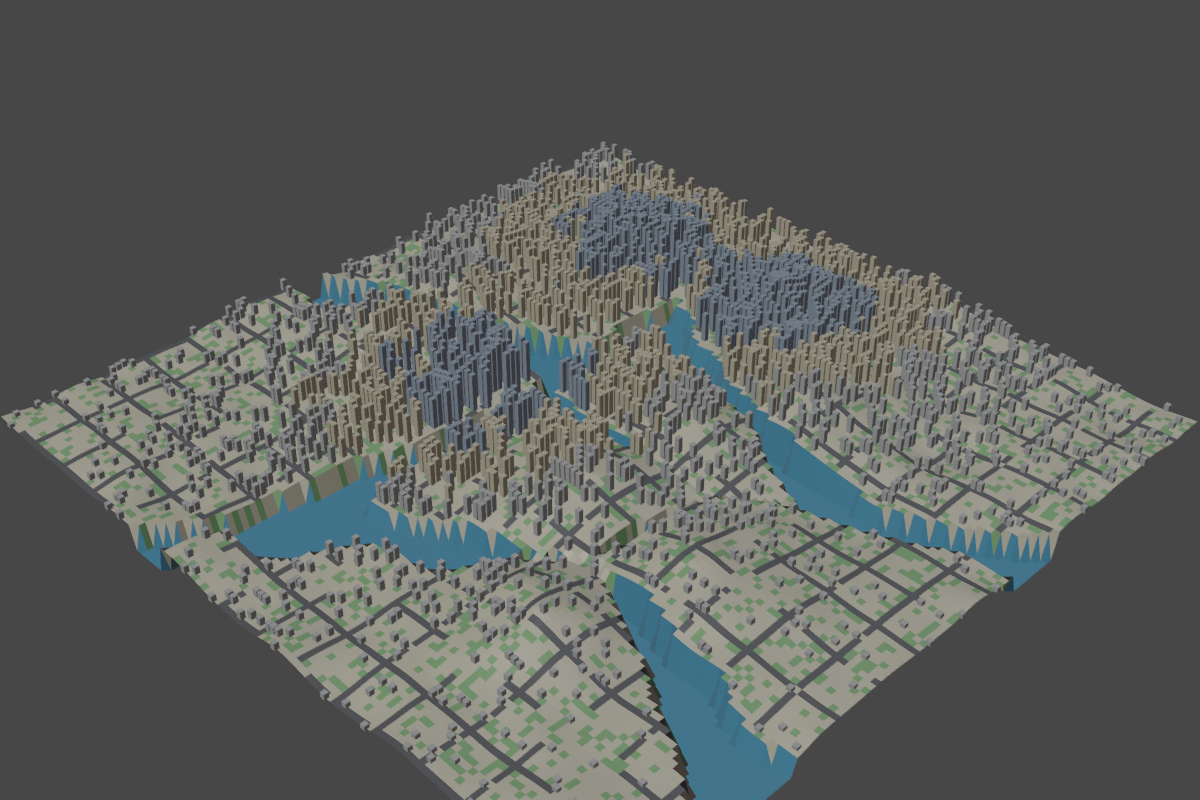

In [20]:
try:
    from IPython.display import Image, display
except ImportError:   # not running under Jupyter
    Image = display = None

preview_png = REPO / "data" / "week3_preview.png"
blend_path = CITY_NPZ.with_suffix(".blend")

if not blend_path.exists():
    print("No .blend yet -- get Part 3 working first.")
else:
    ok_r, _, _ = run_blender("scripts/_render_preview.py", blend_path, preview_png)
    if check("preview rendered", ok_r and preview_png.exists(),
             "Optional step -- if it won't cooperate, just open the .blend in Blender yourself."):
        if display is not None:
            display(Image(filename=str(preview_png)))
        else:
            print("saved to", preview_png)

---

## Reference: the documentation answers

Students write `docs/blender_export.md` themselves. Here's what a complete
answer covers, for marking or for unblocking.

**1. The `.npz`** — `np.savez_compressed` writes five named arrays into one
zip: `size`, `terrain_height` (float32, 0–1), `is_water` (bool),
`building_height` (float32, 0 where none), `land_use` (uint8;
0=empty/1=building/2=road/3=green). `CityGrid.load` reads them straight back.

**2. Grid → vertices** — cell `(y, x)` becomes a vertex at
`(x*CELL_SIZE, y*CELL_SIZE, z)`. `z` is `terrain_height * HEIGHT_SCALE`
because the raw heightmap is 0–1 and would be invisibly flat beside
8-unit buildings. Water is pinned to `0.0` so lakes are level.

**3. Vertices → faces** — each 2×2 block of neighbouring vertices becomes
one quad, `(size-1)²` in total. Winding order must go around the quad;
crossing the diagonal makes bow-tie faces.

**4. Buildings** — 8 vertices and 6 faces per building cell. `half = 0.4`
(not 0.5) leaves a visible gap so neighbours don't fuse into one slab. All
boxes live in **one mesh object**: thousands of separate Blender objects
would make the viewport unusable, thousands of boxes in one mesh is fine.

**5. Materials** — a mesh holds materials in ordered **slots**; each face's
`material_index` points at one. Height tiers use percentiles (40th/75th)
rather than fixed cutoffs so colouring adapts to each city's own range.

**6. Running it** — `blender --background --python script.py -- data/city.npz`.
`--background` is headless; `--` separates Blender's args from the script's.

**7. Gotchas** — `save_as_mainfile` needs an **absolute** path; Blender has
numpy but **not scipy**; the viewport's default Solid shading shows grey, so
switch to **Material Preview** to see colours.

---

## Stretch goal reference: scipy-free connected components

For merging terraced buildings. `scipy.ndimage.label` would be the obvious
tool but **scipy doesn't exist inside Blender**, so:

```python
def connected_components(mask):
    # 4-connectivity connected components, numpy + stdlib only
    h, w = mask.shape
    labels = np.zeros((h, w), dtype=np.int32)
    current = 0
    for sy in range(h):
        for sx in range(w):
            if not mask[sy, sx] or labels[sy, sx]:
                continue
            current += 1
            stack = [(sy, sx)]
            labels[sy, sx] = current
            while stack:                      # explicit stack, not recursion --
                y, x = stack.pop()            # a big region would blow the
                for ny, nx in ((y-1,x),(y+1,x),(y,x-1),(y,x+1)):   # call stack
                    if 0 <= ny < h and 0 <= nx < w and mask[ny,nx] and not labels[ny,nx]:
                        labels[ny,nx] = current
                        stack.append((ny,nx))
    return labels, current
```

Verified to produce identical partitions to
`scipy.ndimage.label(mask, structure=[[0,1,0],[1,1,1],[0,1,0]])`.
